# PR11: Advanced Machine Learning and Model Optimization

**Aim:** Implement SVM, Random Forest and AdaBoost; apply 5-fold cross-validation and Grid Search; compare performance before and after tuning.

**Dataset:** Pima Indians Diabetes dataset (same as the original notebook).

In [22]:
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score


## 1. Import libraries and load dataset

In [23]:
columns = ["buying", "maintenance", "doors", "persons", "luggage", "safety", "class"]
df = pd.read_csv("car_evaluation.csv", header=None, names=columns)
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Dataset shape: (1728, 7)
Missing values: 0


,buying,maintenance,doors,persons,luggage,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 2. Split the data and define models

In [24]:

X = pd.get_dummies(df.drop("class", axis=1), dtype=int)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [25]:
models = {
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

parameters = {
    "SVM": {"svc__C": [1, 10], "svc__kernel": ["linear", "rbf"]},
    "Random Forest": {"n_estimators": [50, 100]},
     # Number of decision trees
    "AdaBoost": {"n_estimators": [50, 100]}
    # Number of Weak Learners
}

In [26]:
results = []

for name, model in models.items():

    # Before optimization
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, y_train, cv=5).mean()

    acc1 = accuracy_score(y_test, pred)
    f1_1 = f1_score(y_test, pred, average="weighted", zero_division=0)

    # After optimization
    grid = GridSearchCV(model, parameters[name], cv=5)
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    pred = best_model.predict(X_test)

    acc2 = accuracy_score(y_test, pred)
    f1_2 = f1_score(y_test, pred, average="weighted", zero_division=0)

    results.append([name, cv, acc1, f1_1, grid.best_score_, acc2, f1_2])

    print(name, grid.best_params_)

comparison = pd.DataFrame(results, columns=[
    "Model", "CV Before", "Accuracy Before", "F1 Before",
    "CV After", "Accuracy After", "F1 After"
])

print(comparison.round(4))

SVM {'svc__C': 10, 'svc__kernel': 'rbf'}
Random Forest {'n_estimators': 50}
AdaBoost {'n_estimators': 100}
           Model  CV Before  Accuracy Before  F1 Before  CV After  \
0            SVM     0.9530           0.9740     0.9742    0.9986   
1  Random Forest     0.9450           0.9682     0.9678    0.9457   
2       AdaBoost     0.8379           0.8439     0.8394    0.8567   

   Accuracy After  F1 After  
0          0.9971    0.9971  
1          0.9711    0.9710  
2          0.8584    0.8525  


## 4. Compare results and conclude

Best model before tuning: SVM
Best model after tuning: SVM


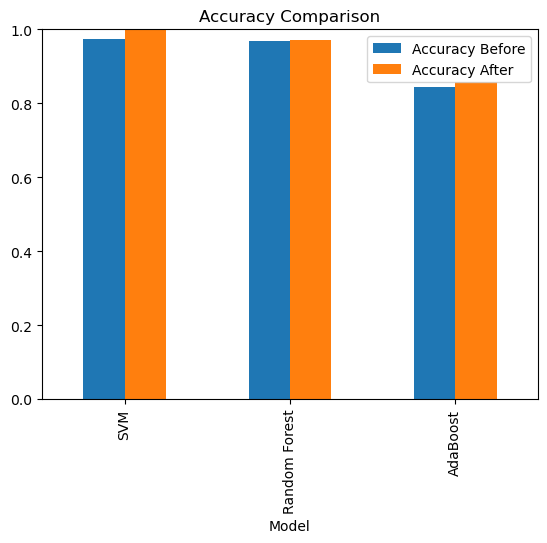

In [27]:
best_before = comparison.loc[comparison["Accuracy Before"].idxmax(), "Model"]
best_after = comparison.loc[comparison["Accuracy After"].idxmax(), "Model"]

print("Best model before tuning:", best_before)
print("Best model after tuning:", best_after)

comparison.plot(x="Model", y=["Accuracy Before", "Accuracy After"],
                kind="bar", ylim=(0, 1), title="Accuracy Comparison");